Challenge 10

Andrea P. Gómez Jaime

In [1]:
import warnings
warnings.filterwarnings("ignore")


In [23]:
import numpy as np
import time
import matplotlib.pyplot as plt
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib
from sklearn.linear_model import LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, r2_score, mean_squared_error, mean_absolute_error, explained_variance_score)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.mixture import GaussianMixture
from sklearn.calibration import calibration_curve
import pandas as pd
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, Ridge, BayesianRidge
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, FastICA
from sklearn.model_selection import cross_val_score, KFold, cross_validate
from sklearn.neural_network import MLPClassifier, MLPRegressor

Part A

In [2]:
brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
yeo = datasets.fetch_atlas_schaefer_2018(n_rois=200) 
print('%i regions found in this atlas' % (len(np.unique( nib.load(yeo.maps).get_fdata().ravel())) - 1))
masker = NiftiLabelsMasker(labels_img=yeo.maps, standardize=True,
memory='nilearn_cache')
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = np.array(brain_data.ext_vars.mf == 'F', dtype=int) # gives 1 for females and 0 for male

[fetch_oasis_vbm] Dataset directory found: C:\Users\Asus\nilearn_data\oasis1
[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018
200 regions found in this atlas


C:\Users\Asus\AppData\Local\Temp\ipykernel_15608\2484280934.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  input_variables = masker.fit_transform(brain_data.gray_matter_maps)


In [3]:
def get_features(labels_img):
    masker = NiftiLabelsMasker(labels_img=labels_img, standardize="zscore_sample",
                               memory='nilearn_cache')
    return masker.fit_transform(brain_data.gray_matter_maps)

def split(X, y, n_train=80):
    return X[:n_train], X[n_train:], y[:n_train], y[n_train:]

Task 1

In [4]:
def run_poly_curve(X, y=output_variable, n_test=10,
                   degrees=[1, 2, 3, 4, 5], n_features=50):
    X = X[:, :n_features]                       # first 50 ROIs only (see note)
    X_train, y_train = X[:-n_test], y[:-n_test]  # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]  # last 10 subjects
    train_acc, test_acc = [], []
    for d in degrees:
        poly = PolynomialFeatures(degree=d)
        P_train = poly.fit_transform(X_train)
        P_test  = poly.transform(X_test)         # reuse the fitted transformer
        clf = LogisticRegression()               # default parameters
        clf.fit(P_train, y_train)
        train_acc.append(accuracy_score(y_train, clf.predict(P_train)))
        test_acc.append(accuracy_score(y_test, clf.predict(P_test)))
    return train_acc, test_acc, degrees


In [5]:
atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100)
X = get_features(atlas.maps)
poly_train_acc, poly_test_acc, poly_n = run_poly_curve(X, output_variable)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


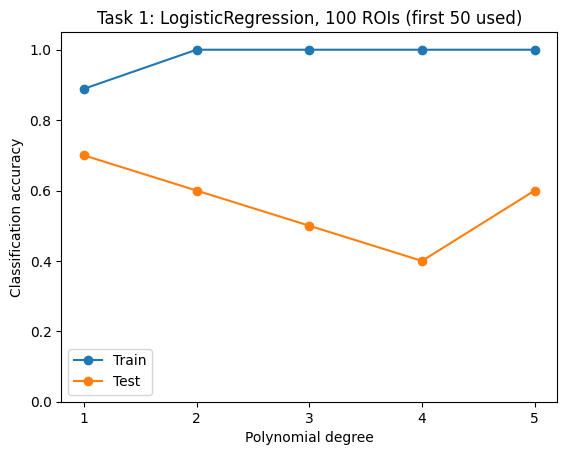

In [6]:
plt.plot(poly_n, poly_train_acc, color='tab:blue', marker='o', label='Train')
plt.plot(poly_n, poly_test_acc,  color='tab:orange', marker='o', label='Test')
plt.xticks(poly_n)
plt.xlabel('Polynomial degree')
plt.ylabel('Classification accuracy')
plt.title('Task 1: LogisticRegression, 100 ROIs (first 50 used)')
plt.ylim(0.0, 1.05)
plt.legend()
plt.show()


Task 2

In [7]:
def run_poly_bayes(X, y=output_variable, n_test=10,
                   degrees=[1, 2, 3, 4, 5], n_features=50):
    X = X[:, :n_features]                        # first 50 ROIs only
    y_pm = 2 * y - 1                             # recode 0/1 -> -1/+1 (female = +1)
    X_train, y_train = X[:-n_test], y_pm[:-n_test]
    X_test,  y_test  = X[-n_test:], y_pm[-n_test:]
    train_acc, test_acc = [], []
    for d in degrees:
        poly = PolynomialFeatures(degree=d)
        P_train = poly.fit_transform(X_train)
        P_test  = poly.transform(X_test)
        reg = BayesianRidge()                    # default parameters
        reg.fit(P_train, y_train)
        # continuous prediction -> threshold at zero -> back to +1/-1
        pred_train = np.where(reg.predict(P_train) > 0, 1, -1)
        pred_test  = np.where(reg.predict(P_test)  > 0, 1, -1)
        train_acc.append(accuracy_score(y_train, pred_train))
        test_acc.append(accuracy_score(y_test, pred_test))
    return train_acc, test_acc, degrees


In [12]:
bayes_train_acc, bayes_test_acc, bayes_n = run_poly_bayes(X, output_variable,
                                                          degrees=[1, 2, 3]) #ran up til 3 because of computational load constraints


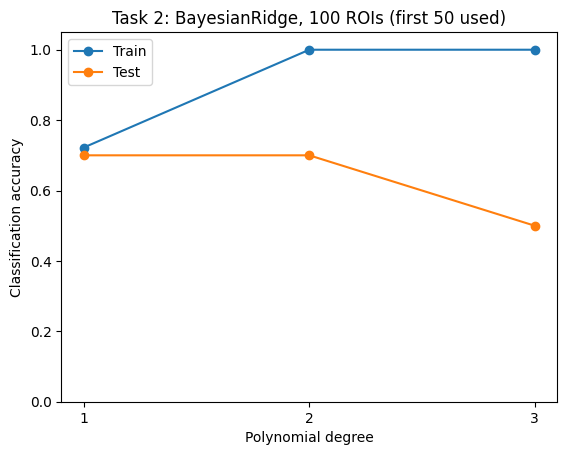

In [13]:
plt.plot(bayes_n, bayes_train_acc, color='tab:blue', marker='o', label='Train')
plt.plot(bayes_n, bayes_test_acc,  color='tab:orange', marker='o', label='Test')
plt.xticks(bayes_n)
plt.xlabel('Polynomial degree')
plt.ylabel('Classification accuracy')
plt.title('Task 2: BayesianRidge, 100 ROIs (first 50 used)')
plt.ylim(0.0, 1.05)
plt.legend()
plt.show()


Task 3

In [14]:
def run_kmeans_poly(X, y=output_variable, n_test=10, ks=range(1, 21),
                    degree=2, n_features=50, seed=0):
    X = X[:, :n_features]
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]      # last 10 subjects

    poly = PolynomialFeatures(degree=degree)
    P_train = poly.fit_transform(X_train)
    P_test  = poly.transform(X_test)

    train_acc, test_acc = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_train)
        train_lab = km.labels_                       # cluster of each training subject
        test_lab  = km.predict(X_test)               # nearest cluster for each test subject

        pred_train = np.zeros(len(y_train), dtype=int)
        pred_test  = np.zeros(len(y_test),  dtype=int)
        for c in range(k):
            tr = train_lab == c
            te = test_lab == c
            if len(np.unique(y_train[tr])) == 1:     # cluster has only one class
                pred_train[tr] = y_train[tr][0]
                pred_test[te]  = y_train[tr][0]
            else:
                clf = LogisticRegression().fit(P_train[tr], y_train[tr])
                pred_train[tr] = clf.predict(P_train[tr])
                if te.any():
                    pred_test[te] = clf.predict(P_test[te])

        train_acc.append(accuracy_score(y_train, pred_train))
        test_acc.append(accuracy_score(y_test, pred_test))
    return train_acc, test_acc, list(ks)


In [15]:
km_train_acc, km_test_acc, km_n = run_kmeans_poly(X, output_variable)


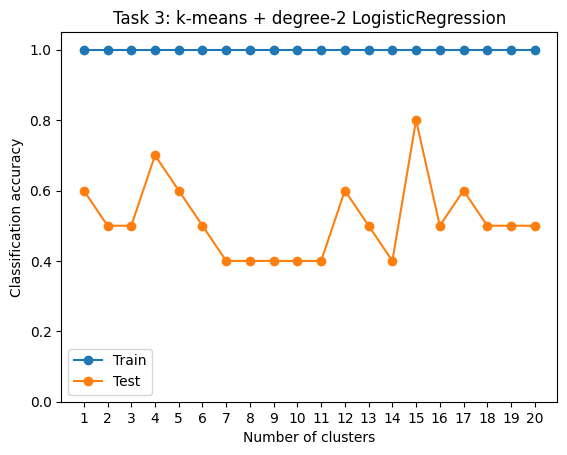

In [16]:
plt.plot(km_n, km_train_acc, color='tab:blue', marker='o', label='Train')
plt.plot(km_n, km_test_acc,  color='tab:orange', marker='o', label='Test')
plt.xticks(km_n)
plt.xlabel('Number of clusters')
plt.ylabel('Classification accuracy')
plt.title('Task 3: k-means + degree-2 LogisticRegression')
plt.ylim(0.0, 1.05)
plt.legend()
plt.show()


Task 4

In [19]:
def run_gmm_poly(X, y=output_variable, n_test=10, ks=range(1, 21),
                 degree=2, n_features=50, seed=0):
    X = X[:, :n_features]
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]      # last 10 subjects

    poly = PolynomialFeatures(degree=degree)
    P_train = poly.fit_transform(X_train)
    P_test  = poly.transform(X_test)
    majority = int(np.round(y_train.mean()))         # fallback if a component is empty

    train_acc, test_acc = [], []
    for k in ks:
        gmm = GaussianMixture(n_components=k, n_init=10, random_state=seed,
                      reg_covar=1e-3).fit(X_train)

        train_lab = gmm.predict(X_train)             # most likely component per subject
        test_lab  = gmm.predict(X_test)

        pred_train = np.zeros(len(y_train), dtype=int)
        pred_test  = np.zeros(len(y_test),  dtype=int)
        for c in range(k):
            tr = train_lab == c
            te = test_lab == c
            if tr.sum() == 0:                        # no training subject in this component
                pred_test[te] = majority
            elif len(np.unique(y_train[tr])) == 1:   # only one class in this component
                pred_train[tr] = y_train[tr][0]
                pred_test[te]  = y_train[tr][0]
            else:
                clf = LogisticRegression().fit(P_train[tr], y_train[tr])
                pred_train[tr] = clf.predict(P_train[tr])
                if te.any():
                    pred_test[te] = clf.predict(P_test[te])

        train_acc.append(accuracy_score(y_train, pred_train))
        test_acc.append(accuracy_score(y_test, pred_test))
    return train_acc, test_acc, list(ks)


In [20]:
gmm_train_acc, gmm_test_acc, gmm_n = run_gmm_poly(X, output_variable)


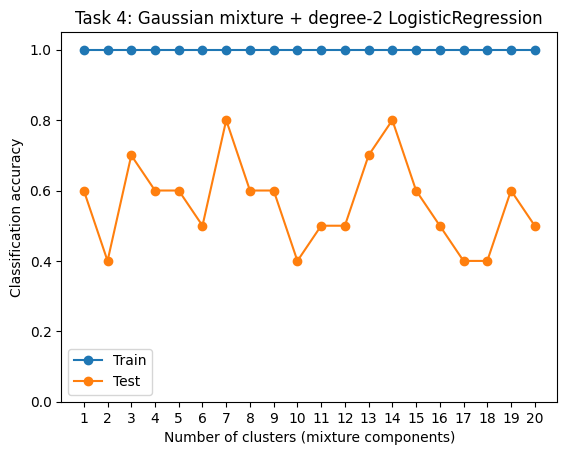

In [21]:
plt.plot(gmm_n, gmm_train_acc, color='tab:blue', marker='o', label='Train')
plt.plot(gmm_n, gmm_test_acc,  color='tab:orange', marker='o', label='Test')
plt.xticks(gmm_n)
plt.xlabel('Number of clusters (mixture components)')
plt.ylabel('Classification accuracy')
plt.title('Task 4: Gaussian mixture + degree-2 LogisticRegression')
plt.ylim(0.0, 1.05)
plt.legend()
plt.show()


Task 5

In [24]:
def run_poly_bayes_time(X, y=output_variable, n_test=10,
                        degrees=[1, 2, 3], n_features=50, n_repeats=1):
    X = X[:, :n_features]                         # first 50 ROIs (PDF note)
    y_pm = 2 * y - 1                              # +1 / -1, as in Task 2 because output is 1 or 0
    X_train, y_train = X[:-n_test], y_pm[:-n_test]   # first 90 subjects
    times_ms = []
    for d in degrees:
        P_train = PolynomialFeatures(degree=d).fit_transform(X_train)
        runs = []
        for i in range(n_repeats):
            reg = BayesianRidge()                 # default parameters
            t0 = time.perf_counter()
            reg.fit(P_train, y_train)             # only the fit is timed
            runs.append((time.perf_counter() - t0) * 1000)   # seconds -> ms
        times_ms.append(np.median(runs))
    return times_ms, degrees


In [25]:
fit_ms, fit_n = run_poly_bayes_time(X, output_variable)
print(dict(zip(fit_n, np.round(fit_ms, 1))))


{1: np.float64(4.1), 2: np.float64(73.7), 3: np.float64(61190.7)}


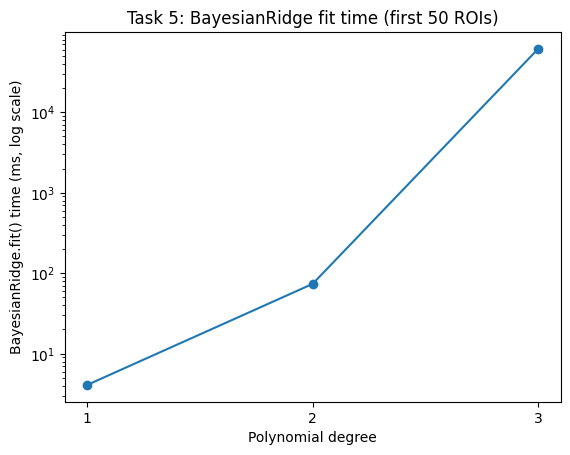

In [26]:
plt.plot(fit_n, fit_ms, color='tab:blue', marker='o')
plt.yscale('log')
plt.xticks(fit_n)
plt.xlabel('Polynomial degree')
plt.ylabel('BayesianRidge.fit() time (ms, log scale)')
plt.title('Task 5: BayesianRidge fit time (first 50 ROIs)')
plt.show()


Part B

In [42]:
brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
crad = {'scorr_mean': 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'}
atlas_nii = index_img(crad['scorr_mean'], 0)      # lowest resolution (10 regions)
print('%i regions found in this atlas' % (len(np.unique(atlas_nii.get_fdata().ravel())) - 1))
masker = NiftiLabelsMasker(labels_img= atlas_nii, standardize=True)
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age.to_numpy()[:, None])[:,
0] # gives subject age on standard units after z-scoring

[fetch_oasis_vbm] Dataset directory found: C:\Users\Asus\nilearn_data\oasis1
10 regions found in this atlas


C:\Users\Asus\AppData\Local\Temp\ipykernel_15608\476709972.py:6: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  input_variables = masker.fit_transform(brain_data.gray_matter_maps)


In [43]:
n_resolutions = nib.load(crad['scorr_mean']).shape[-1]  # should be 43
print(f"Number of resolutions in the Craddock atlas: {n_resolutions}")
craddock_indices = np.arange(n_resolutions)

def get_craddock_labels_img(idx):
    return index_img(crad['scorr_mean'], idx)


Number of resolutions in the Craddock atlas: 43


Task 6

In [44]:
def run_poly_ridge(X, y, n_test=10, degrees=[1, 2, 3, 4, 5], n_features=50):
    X = X[:, :n_features]                             # PDF note (keeps all 10 here)
    X_train, y_train = X[:-n_test], y[:-n_test]       # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]       # last 10 subjects
    train_r2, test_r2 = [], []
    for d in degrees:
        poly = PolynomialFeatures(degree=d)
        P_train = poly.fit_transform(X_train)
        P_test  = poly.transform(X_test)
        reg = Ridge()                                 # default parameters
        reg.fit(P_train, y_train)
        train_r2.append(r2_score(y_train, reg.predict(P_train)))
        test_r2.append(r2_score(y_test,  reg.predict(P_test)))
    return train_r2, test_r2, degrees


In [45]:
X_crad = get_features(atlas_nii)
ridge_train_r2, ridge_test_r2, ridge_n = run_poly_ridge(X_crad, output_variable)


c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: Ill-conditioned matrix (rcond=4.45166e-09): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: Ill-conditioned matrix (rcond=7.79801e-13): result may not be accurate.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


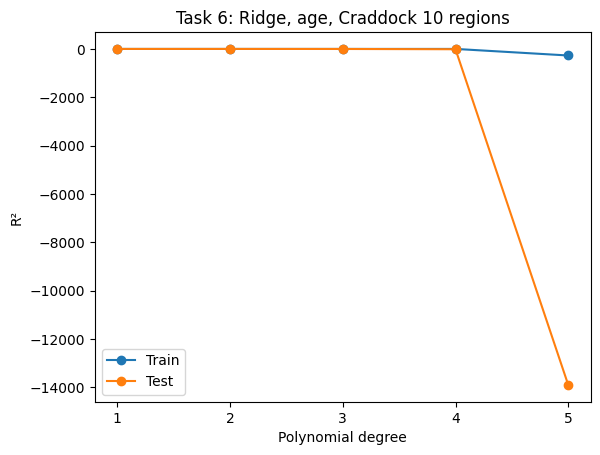

In [47]:
plt.plot(ridge_n, ridge_train_r2, color='tab:blue', marker='o', label='Train')
plt.plot(ridge_n, ridge_test_r2,  color='tab:orange', marker='o', label='Test')
plt.xticks(ridge_n)
plt.xlabel('Polynomial degree')
plt.ylabel('R²')
plt.title('Task 6: Ridge, age, Craddock 10 regions')
plt.legend()
plt.show()


Task 7

In [48]:
def run_poly_bayes_age(X, y=output_variable, n_test=10,
                       degrees=[1, 2, 3, 4, 5]):
    X = X[:, 0:50]                                   # PDF note (keeps all 10 columns here)
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]      # last 10 subjects
    train_r2, test_r2 = [], []
    for d in degrees:
        poly = PolynomialFeatures(degree=d)
        P_train = poly.fit_transform(X_train)
        P_test  = poly.transform(X_test)
        reg = BayesianRidge()                        # default parameters
        reg.fit(P_train, y_train)
        train_r2.append(r2_score(y_train, reg.predict(P_train)))   # continuous, no threshold
        test_r2.append(r2_score(y_test,  reg.predict(P_test)))
    return train_r2, test_r2, degrees


In [49]:
bayes_age_train_r2, bayes_age_test_r2, bayes_age_n = run_poly_bayes_age(X_crad, output_variable, degrees=[1, 2, 3])


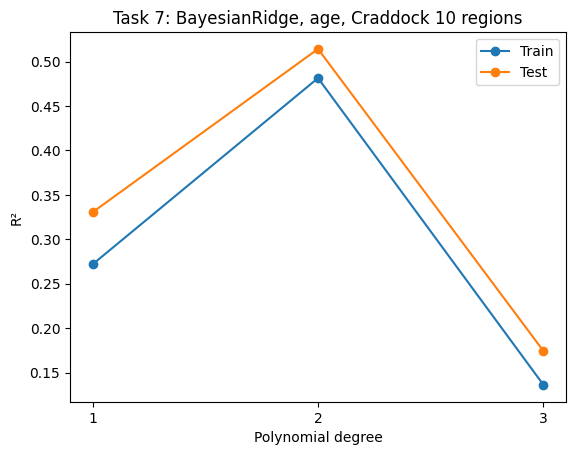

In [50]:
plt.plot(bayes_age_n, bayes_age_train_r2, color='tab:blue', marker='o', label='Train')
plt.plot(bayes_age_n, bayes_age_test_r2,  color='tab:orange', marker='o', label='Test')
plt.xticks(bayes_age_n)
plt.xlabel('Polynomial degree')
plt.ylabel('R²')
plt.title('Task 7: BayesianRidge, age, Craddock 10 regions')
plt.legend()
plt.show()


Task 8

In [51]:
def run_kmeans_poly_ridge(X, y=output_variable, n_test=10, ks=range(1, 21),
                          degree=2, seed=0):
    X = X[:, 0:50]                                   # PDF note (keeps all 10 columns here)
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]      # last 10 subjects

    poly = PolynomialFeatures(degree=degree)
    P_train = poly.fit_transform(X_train)
    P_test  = poly.transform(X_test)

    train_r2, test_r2 = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_train)
        train_lab = km.labels_
        test_lab  = km.predict(X_test)

        pred_train = np.zeros(len(y_train))
        pred_test  = np.zeros(len(y_test))
        for c in range(k):
            tr = train_lab == c
            te = test_lab == c
            reg = Ridge().fit(P_train[tr], y_train[tr])   # this cluster's model
            pred_train[tr] = reg.predict(P_train[tr])
            if te.any():
                pred_test[te] = reg.predict(P_test[te])

        train_r2.append(r2_score(y_train, pred_train))
        test_r2.append(r2_score(y_test,  pred_test))
    return train_r2, test_r2, list(ks)


In [52]:
km_age_train_r2, km_age_test_r2, km_age_n = run_kmeans_poly_ridge(X_crad, output_variable)


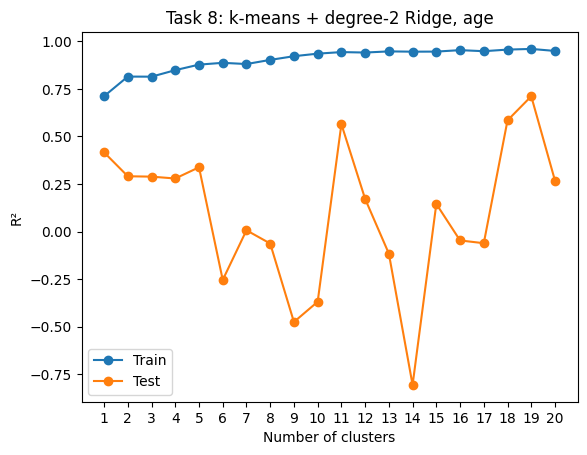

In [53]:
plt.plot(km_age_n, km_age_train_r2, color='tab:blue', marker='o', label='Train')
plt.plot(km_age_n, km_age_test_r2,  color='tab:orange', marker='o', label='Test')
plt.xticks(km_age_n)
plt.xlabel('Number of clusters')
plt.ylabel('R²')
plt.title('Task 8: k-means + degree-2 Ridge, age')
plt.legend()
plt.show()


Task 9

In [54]:
def run_gmm_poly_ridge(X, y=output_variable, n_test=10, ks=range(1, 21),
                       degree=2, seed=0):
    X = X[:, 0:50]                                   # PDF note (keeps all 10 columns here)
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    X_test,  y_test  = X[-n_test:], y[-n_test:]      # last 10 subjects

    poly = PolynomialFeatures(degree=degree)
    P_train = poly.fit_transform(X_train)
    P_test  = poly.transform(X_test)
    mean_age = y_train.mean()                        # fallback if a component is empty

    train_r2, test_r2 = [], []
    for k in ks:
        gmm = GaussianMixture(n_components=k, n_init=10, random_state=seed).fit(X_train)
        train_lab = gmm.predict(X_train)             # most likely component per subject
        test_lab  = gmm.predict(X_test)

        pred_train = np.zeros(len(y_train))
        pred_test  = np.zeros(len(y_test))
        for c in range(k):
            tr = train_lab == c
            te = test_lab == c
            if tr.sum() == 0:                        # no training subject in this component
                pred_test[te] = mean_age
                continue
            reg = Ridge().fit(P_train[tr], y_train[tr])
            pred_train[tr] = reg.predict(P_train[tr])
            if te.any():
                pred_test[te] = reg.predict(P_test[te])

        train_r2.append(r2_score(y_train, pred_train))
        test_r2.append(r2_score(y_test,  pred_test))
    return train_r2, test_r2, list(ks)


In [55]:
gmm_age_train_r2, gmm_age_test_r2, gmm_age_n = run_gmm_poly_ridge(X_crad, output_variable)


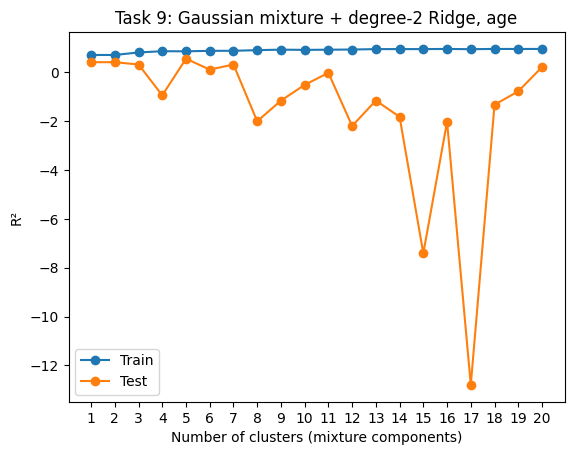

In [56]:
plt.plot(gmm_age_n, gmm_age_train_r2, color='tab:blue', marker='o', label='Train')
plt.plot(gmm_age_n, gmm_age_test_r2,  color='tab:orange', marker='o', label='Test')
plt.xticks(gmm_age_n)
plt.xlabel('Number of clusters (mixture components)')
plt.ylabel('R²')
plt.title('Task 9: Gaussian mixture + degree-2 Ridge, age')
plt.legend()
plt.show()


Task 10

In [57]:
def run_poly_bayes_time_age(X, y=output_variable, n_test=10,
                            degrees=[1, 2, 3, 4, 5], n_repeats=5):
    X = X[:, 0:50]                                   # PDF note (keeps all 10 columns here)
    X_train, y_train = X[:-n_test], y[:-n_test]      # first 90 subjects
    times_ms = []
    for d in degrees:
        P_train = PolynomialFeatures(degree=d).fit_transform(X_train)
        runs = []
        for _ in range(n_repeats):
            reg = BayesianRidge()                    # default parameters
            t0 = time.perf_counter()
            reg.fit(P_train, y_train)                # only the fit is timed
            runs.append((time.perf_counter() - t0) * 1000)   # seconds -> ms
        times_ms.append(np.median(runs))
    return times_ms, degrees


In [58]:
fit_age_ms, fit_age_n = run_poly_bayes_time_age(X_crad, output_variable)
print(dict(zip(fit_age_n, np.round(fit_age_ms, 1))))


{1: np.float64(0.6), 2: np.float64(3.3), 3: np.float64(20.3), 4: np.float64(47.4), 5: np.float64(280.6)}


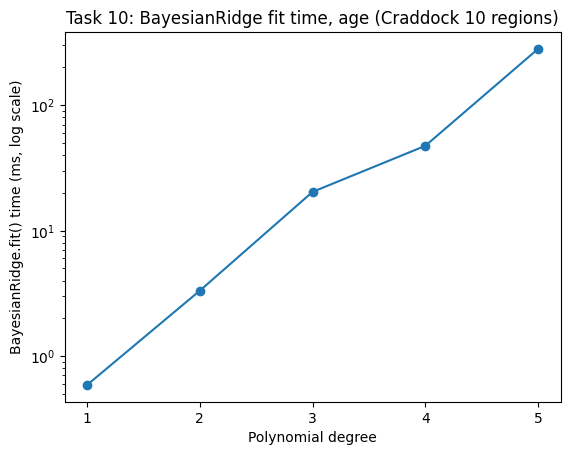

In [59]:
plt.plot(fit_age_n, fit_age_ms, color='tab:blue', marker='o')
plt.yscale('log')
plt.xticks(fit_age_n)
plt.xlabel('Polynomial degree')
plt.ylabel('BayesianRidge.fit() time (ms, log scale)')
plt.title('Task 10: BayesianRidge fit time, age (Craddock 10 regions)')
plt.show()
